In [11]:
import pandas as pd
import numpy as np
import requests
from io import StringIO
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder

In [12]:
#set out api_key
 
API_KEY = 'JHWM2SB-Y7D4EPT-NCD78X0-G96BVZK'

In [13]:
#get data from a single station 

def get_sm_data (ID,start,end,variables,res,API_KEY):
    
    #create our base url for the airquality egg api 
    base_url = f"https://airqualityegg.com/api/v2/messages/device/{ID}"

    # Set up the query parameters for the API request
    params = {
        "apiKey": API_KEY,
        "format": "csv",  # Request data in CSV format but doesn't have to be csv 
        "start-date": start,
        "end-date": end,
        "resolution": f"PT{res}"  } # Add 'PT' prefix to resolution

    # Send GET request to the API
    response = requests.get(base_url, params=params, timeout=20) 

    # Raise an exception for bad responses
    response.raise_for_status()

    # Parse the CSV response into a pandas DataFrame
    data = pd.read_csv(StringIO(response.text))
    
    # Print shape of received data for reference 
    print(f"Received data shape: {data.shape}")

    # Filter the DataFrame to include only the requested variables 
    available_vars = [var for var in variables if var in data.columns]

    # Return the filtered DataFrame with time column and available variables
    return data[['time'] + available_vars]

In [14]:
#to get data from multimple sensors be wary, very slow 

def get_multi_sm_data(IDs, start, end, variables, res, API_KEY):

    if isinstance(IDs, str):
        IDs = [IDs]  # Convert ID to list 

    data_dict = {}

    for ID in IDs:
        base_url = f"https://airqualityegg.com/api/v2/messages/device/{ID}"
        params = {
            "apiKey": API_KEY,
            "format": "csv",
            "start-date": start,
            "end-date": end,
            "resolution": f"PT{res}"
        }

        response = requests.get(base_url, params=params, timeout=20)
        response.raise_for_status()
        data = pd.read_csv(StringIO(response.text))
        print(f"Received data shape for sensor {ID}: {data.shape}")

        available_vars = [var for var in variables if var in data.columns]
        data_dict[ID] = data[['time'] + available_vars]

#return the data as a data dictionary with all of the columns of each sensor 
    return data_dict

In [15]:
#plot data from a single sensor 

def plot_sm_data(data,ID):
    """
    Plot the Air Quality Egg data with time on the x-axis in D/M/Y format.
    Args:
        data (pandas.DataFrame): DataFrame containing the data to plot.
    """
    # Convert the 'time' column to datetime so I can reformat it for plotting 
    data['time'] = pd.to_datetime(data['time'])
    
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(12, 6))
    
    # Plot soil moisture data
    soil_moisture = data['soilmoisture[percent]']
    ax.plot(data['time'], soil_moisture, label=str(ID), color='#1f77b4')
    
    # Customize the plot
    ax.set_xlabel('Date')
    ax.set_ylabel('Volumetric Water Content (%)')
    ax.set_title('Soil Moisture Over Time')
    
    
    # Format x-axis
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y'))
    plt.xticks(rotation=0)
    
    # Add gridlines
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Add legend and mean value annotation
    ax.legend(loc='upper right')
 
    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()   

In [16]:
#to plot multiple ssensors
def plot_multi_sensor_data(sensor_ids, start, end, variables, res, API_KEY):
    """
    Retrieve and plot the Air Quality Egg data for multiple sensors with time on the x-axis in D/M/Y format."""
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(20, 8))
    
    # Color cycle for different sensors because I couldn't decide on colors 
    colors = np.random.rand(len(sensor_ids), 3)
    
    for sensor_id, color in zip(sensor_ids, colors):
        # Retrieve data for the current sensor
        data = get_sm_data(sensor_id, start, end, variables, res, API_KEY)
        
        # Convert the 'time' column to datetime 
        data['time'] = pd.to_datetime(data['time'])
        
        # Plot soil moisture data vs time 
        if 'soilmoisture[percent]' in data.columns:
            soil_moisture = data['soilmoisture[percent]']
            ax.plot(data['time'], soil_moisture, label=f'Sensor {sensor_id}', color=color)
            
        else:
            print(f"Warning: 'soilmoisture[percent]' not found for Sensor {sensor_id}")
    
    # label plot 
    ax.set_xlabel('Date')
    ax.set_ylabel('Volumetric Water Content (%)')
    ax.set_title('Soil Moisture Over Time')
    
    # Format x-axis so date is in the format i want 
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y'))
    plt.xticks(rotation=45)
    
    # Add gridlines 
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Add legend
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()

In [17]:
#to plot multiple ssensors
def plot_multi_sensor_data(sensor_ids, start, end, variables, res, API_KEY):
    """
    Retrieve and plot the Air Quality Egg data for multiple sensors with time on the x-axis in D/M/Y format."""
    # Create a figure and axis
    fig, ax = plt.subplots(figsize=(20, 8))
    
    # Color cycle for different sensors because I couldn't decide on colors 
    colors = np.random.rand(len(sensor_ids), 3)
    
    for sensor_id, color in zip(sensor_ids, colors):
        # Retrieve data for the current sensor
        data = get_sm_data(sensor_id, start, end, variables, res, API_KEY)
        
        # Convert the 'time' column to datetime 
        data['time'] = pd.to_datetime(data['time'])
        
        # Plot soil moisture data vs time 
        if 'soilmoisture[percent]' in data.columns:
            soil_moisture = data['soilmoisture[percent]']
            ax.plot(data['time'], soil_moisture, label=f'Sensor {sensor_id}', color=color)
            
        else:
            print(f"Warning: 'soilmoisture[percent]' not found for Sensor {sensor_id}")
    
    # label plot 
    ax.set_xlabel('Date')
    ax.set_ylabel('Volumetric Water Content (%)')
    ax.set_title('Soil Moisture Over Time')
    
    # Format x-axis so date is in the format i want 
    ax.xaxis.set_major_locator(mdates.AutoDateLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d/%y'))
    plt.xticks(rotation=45)
    
    # Add gridlines 
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Add legend
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
    
    # Adjust layout and display the plot
    plt.tight_layout()
    plt.show()

Lets work on some statistics 

Received data shape: (1310, 5)
Received data shape: (1312, 5)

Shape of dataX after alignment: (1310, 1)
Shape of dataY after alignment: (1310, 2)

Model Summary:
                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.156
Method:                 Least Squares   F-statistic:                     243.8
Date:                Fri, 04 Oct 2024   Prob (F-statistic):           1.56e-50
Time:                        22:06:20   Log-Likelihood:                -2002.2
No. Observations:                1310   AIC:                             4008.
Df Residuals:                    1308   BIC:                             4019.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t    

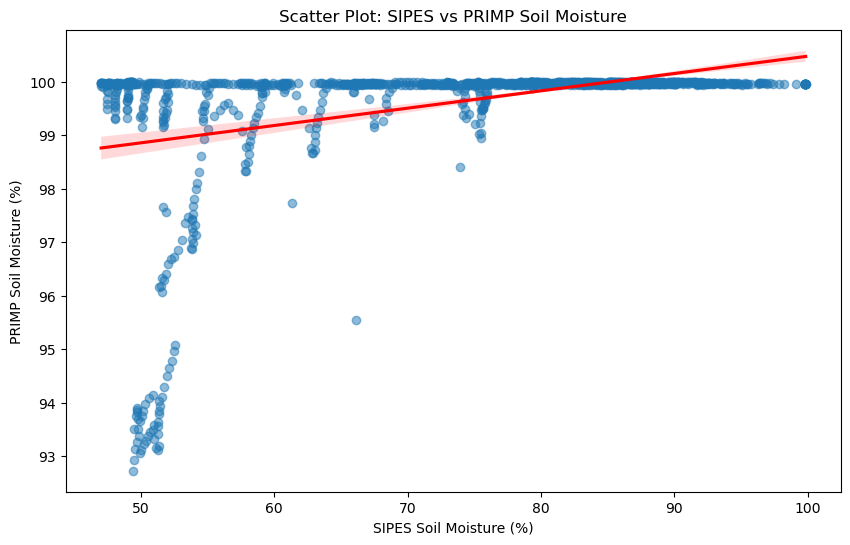

In [21]:
#lets do some statistics for fun 

#running a linear regression between two sensors one at MoE and one at CNC 
# List of sensor IDs
sensor_ids = ["SIPES"]
sensor_data = {}

# Retrieve data for each sensor
for sensor_id in sensor_ids:
    data = get_sm_data(
        ID=sensor_id,
        start="2024-08-01T00:00:00.000Z",
        end="2024-09-25T00:00:00.000Z",
        variables=['soilmoisture[percent]'],
        res="1H",
        API_KEY=API_KEY
    )
    
    # Store the data in the dictionary
    sensor_data[sensor_id] = data['soilmoisture[percent]']

# Combine data from all sensors
dataX = pd.DataFrame(sensor_data)

# Fetch data for VAULT (target variable)
dataY = get_sm_data(
        ID="PRIMP",
        start="2024-08-01T00:00:00.000Z",
        end="2024-09-25T00:00:00.000Z",
        variables=['soilmoisture[percent]'],
        res="1H",
        API_KEY=API_KEY
    )

# Ensure dataX and dataY have the same index for regression 
common_index = dataX.index.intersection(dataY.index)
dataX = dataX.loc[common_index]
dataY = dataY.loc[common_index]
print(f"\nShape of dataX after alignment: {dataX.shape}")
print(f"Shape of dataY after alignment: {dataY.shape}")

# Handle missing values
dataX = dataX.dropna()
dataY = dataY.dropna()

# Ensure dataX and dataY still have the same index after handling missing values
common_index = dataX.index.intersection(dataY.index)
dataX = dataX.loc[common_index]
dataY = dataY.loc[common_index]

# Convert to numpy arrays
X = dataX.values
y = dataY['soilmoisture[percent]'].values

# Add a constant to the predictor variable (for the intercept)
X = sm.add_constant(X)

# Create a linear regression model and fit it
model = sm.OLS(y, X).fit()

# Display the model summary
print("\nModel Summary:")
print(model.summary())

plt.figure(figsize=(10, 6))
sns.regplot(x=dataX.values.flatten(), y=y, 
            scatter_kws={'alpha':0.5}, 
            line_kws={'color': 'red'})
plt.xlabel("SIPES Soil Moisture (%)")
plt.ylabel("PRIMP Soil Moisture (%)")
plt.title("Scatter Plot: SIPES vs PRIMP Soil Moisture")
plt.show()

Received data shape: (1310, 5)
Received data shape: (1321, 5)
Received data shape: (1321, 5)
Received data shape: (1312, 5)
                            OLS Regression Results                            
Dep. Variable:                  VAULT   R-squared:                       0.047
Model:                            OLS   Adj. R-squared:                  0.045
Method:                 Least Squares   F-statistic:                     21.70
Date:                Fri, 04 Oct 2024   Prob (F-statistic):           1.02e-13
Time:                        22:05:57   Log-Likelihood:                -2207.5
No. Observations:                1310   AIC:                             4423.
Df Residuals:                    1306   BIC:                             4444.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-------

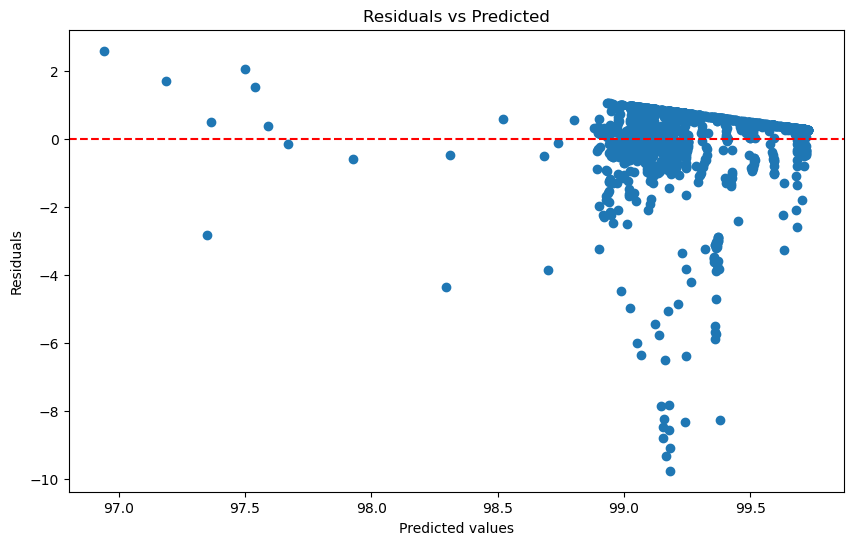

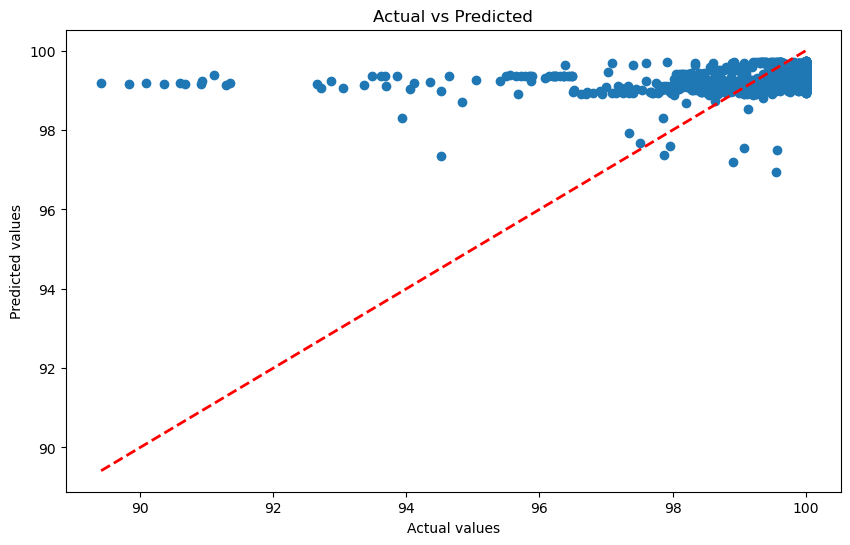

In [19]:
#multiple linear regression


# List of sensor IDs
sensor_ids = ["SIPES", "KOURA", "SKEWS", "VAULT"]
sensor_data = {}

# Retrieve data for each sensor
for sensor_id in sensor_ids:
    data = get_sm_data(
        ID=sensor_id,
        start="2024-08-01T00:00:00.000Z",
        end="2024-09-25T00:00:00.000Z",
        variables=['soilmoisture[percent]'],
        res="1H",
        API_KEY=API_KEY
    )
    
    # Store the data in the dictionary
    sensor_data[sensor_id] = data['soilmoisture[percent]']

# Combine data from all sensors
combined_data = pd.DataFrame(sensor_data)

# Separate features (X) and target variable (y)
X = combined_data.drop('VAULT', axis=1)
y = combined_data['VAULT']

# Handle missing values
X = X.dropna()
y = y[X.index]  # Ensure y has the same index as X

# Add a constant term to the features (required for statsmodels OLS)
X = sm.add_constant(X)

# Fit the multiple linear regression model
model = sm.OLS(y, X).fit()

# Display the model summary
print(model.summary())

plt.figure(figsize=(10, 6))
plt.scatter(model.predict(), model.resid)
plt.xlabel("Predicted values")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted")
plt.axhline(y=0, color='r', linestyle='--')
plt.show()

# Plot actual vs predicted
plt.figure(figsize=(10, 6))
plt.scatter(y, model.predict())
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Actual vs Predicted")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.show()

Received data shape: (1310, 5)
Received data shape: (1321, 5)
Received data shape: (1321, 5)
Received data shape: (1312, 5)

Covariance Matrix of Soil Moisture:
            SIPES       KOURA      SKEWS     VAULT
SIPES  221.248632  168.672786  16.716878 -3.839195
KOURA  168.672786  202.307838  26.262751 -2.920174
SKEWS   16.716878   26.262751  35.696319 -1.058398
VAULT   -3.839195   -2.920174  -1.058398  1.787753

Correlation Matrix of Soil Moisture:
          SIPES     KOURA     SKEWS     VAULT
SIPES  1.000000  0.797560  0.187383 -0.192955
KOURA  0.797560  1.000000  0.309045 -0.153587
SKEWS  0.187383  0.309045  1.000000 -0.132073
VAULT -0.192955 -0.153587 -0.132073  1.000000


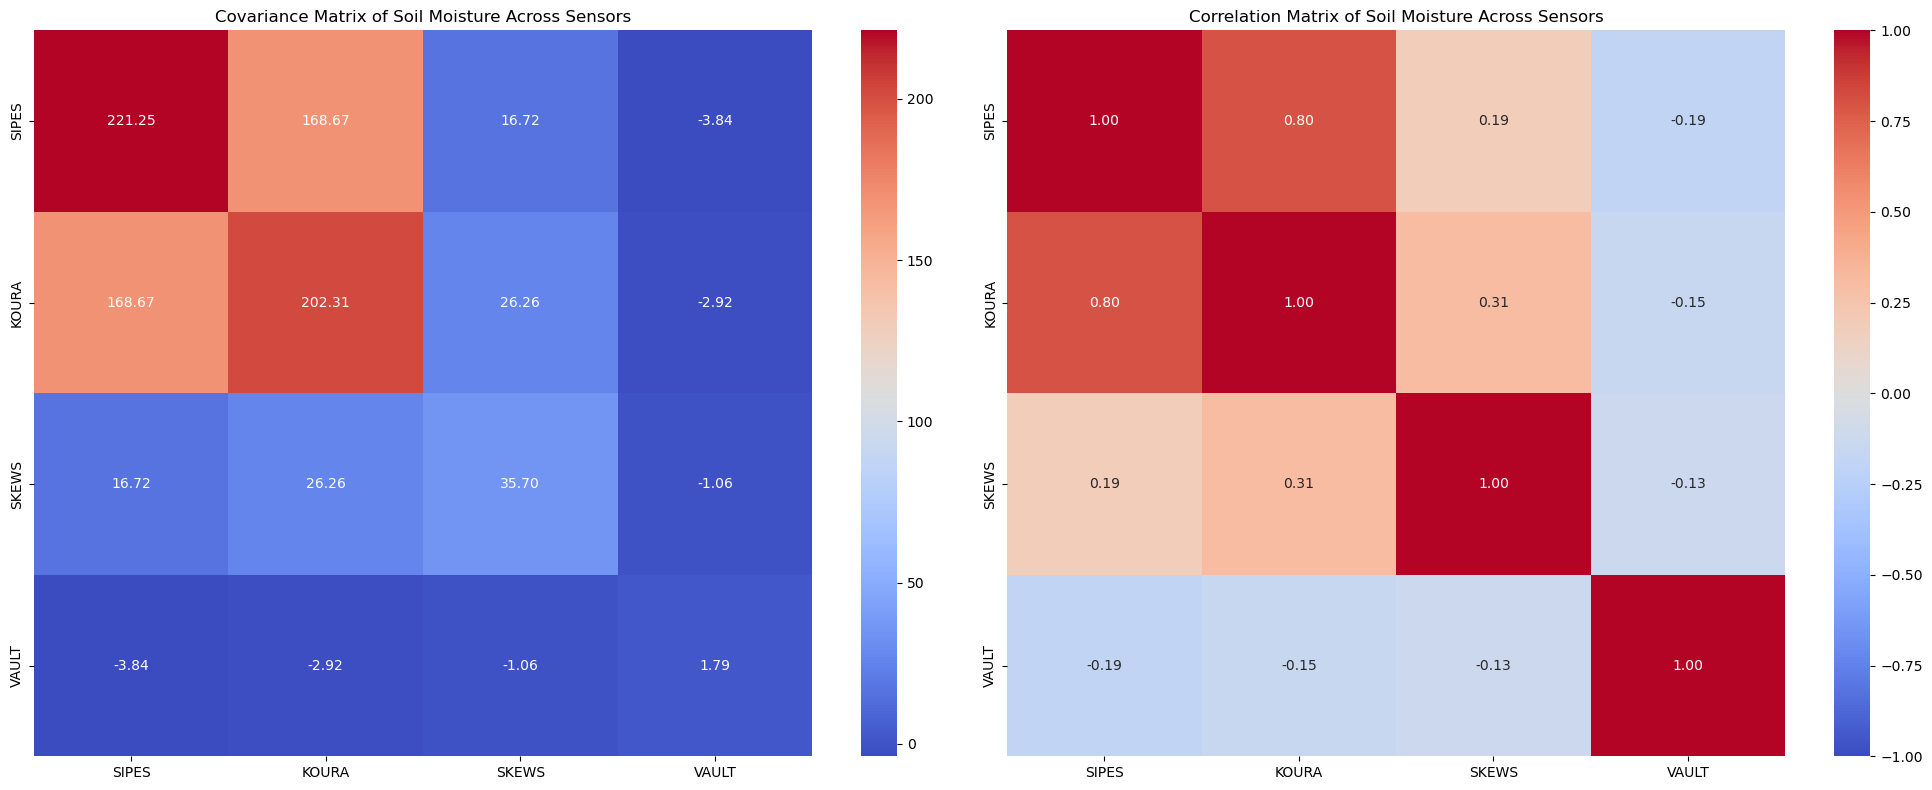

In [20]:
#more statistics!
#lets do some covariance matrices 

sensor_ids = ["SIPES", "KOURA", "SKEWS", "VAULT"]

# Initialize an empty dictionary to store data for each sensor
sensor_data = {}

# Retrieve data for each sensor
for sensor_id in sensor_ids:
    data = get_sm_data(
        ID=sensor_id,
        start="2024-08-01T00:00:00.000Z",
        end="2024-09-25T00:00:00.000Z",
        variables = ['soilmoisture[percent]'],
        res="1H",
        API_KEY=API_KEY
    )
    
    # Print the first few rows of the retrieved data
    '''print(f"\nFiltered soil moisture data for {sensor_id}:")
    print(data.head())'''
    
    # Store the data in the dictionary
    sensor_data[sensor_id] = data['soilmoisture[percent]']

# Combine data from all sensors
combined_data = pd.DataFrame(sensor_data)

# Calculate the covariance and correlation matrices
covariance_matrix = combined_data.cov()
correlation_matrix = combined_data.corr()

print("\nCovariance Matrix of Soil Moisture:")
print(covariance_matrix)

print("\nCorrelation Matrix of Soil Moisture:")
print(correlation_matrix)

#visualize the matrices 

# Create a figure with two subplots side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

# Plot covariance matrix heatmap
sns.heatmap(covariance_matrix, annot=True, cmap='coolwarm', fmt='.2f', ax=ax1)
ax1.set_title('Covariance Matrix of Soil Moisture Across Sensors')

# Plot correlation matrix heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.2f', ax=ax2)
ax2.set_title('Correlation Matrix of Soil Moisture Across Sensors')

# Adjust layout and display the plot
plt.tight_layout()
plt.show()